# 

In [109]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

In [110]:
# Load Data

# Column names from the dataset's .names file
column_names = ['symboling', 'normalized-losses', 'make', 'fuel-type', 'aspiration','num-of-doors', 'body-style', 'drive-wheels', 'engine-location',
               'wheel-base', 'length', 'width', 'height', 'curb-weight', 'engine-type', 'num-of-cylinders', 'engine-size', 'fuel-system',
               'bore', 'stroke', 'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg', 'price']

relative_path = 'datasets/automobile/automobile/imports-85.data'

# Load data, recognising '?' as NaN
data = pd.read_csv(relative_path, header=None, names=column_names, sep=',', na_values='?')

print(f"Data loaded from {relative_path}.")
print(f"Initial shape: {data.shape}")

Data loaded from datasets/automobile/automobile/imports-85.data.
Initial shape: (205, 26)


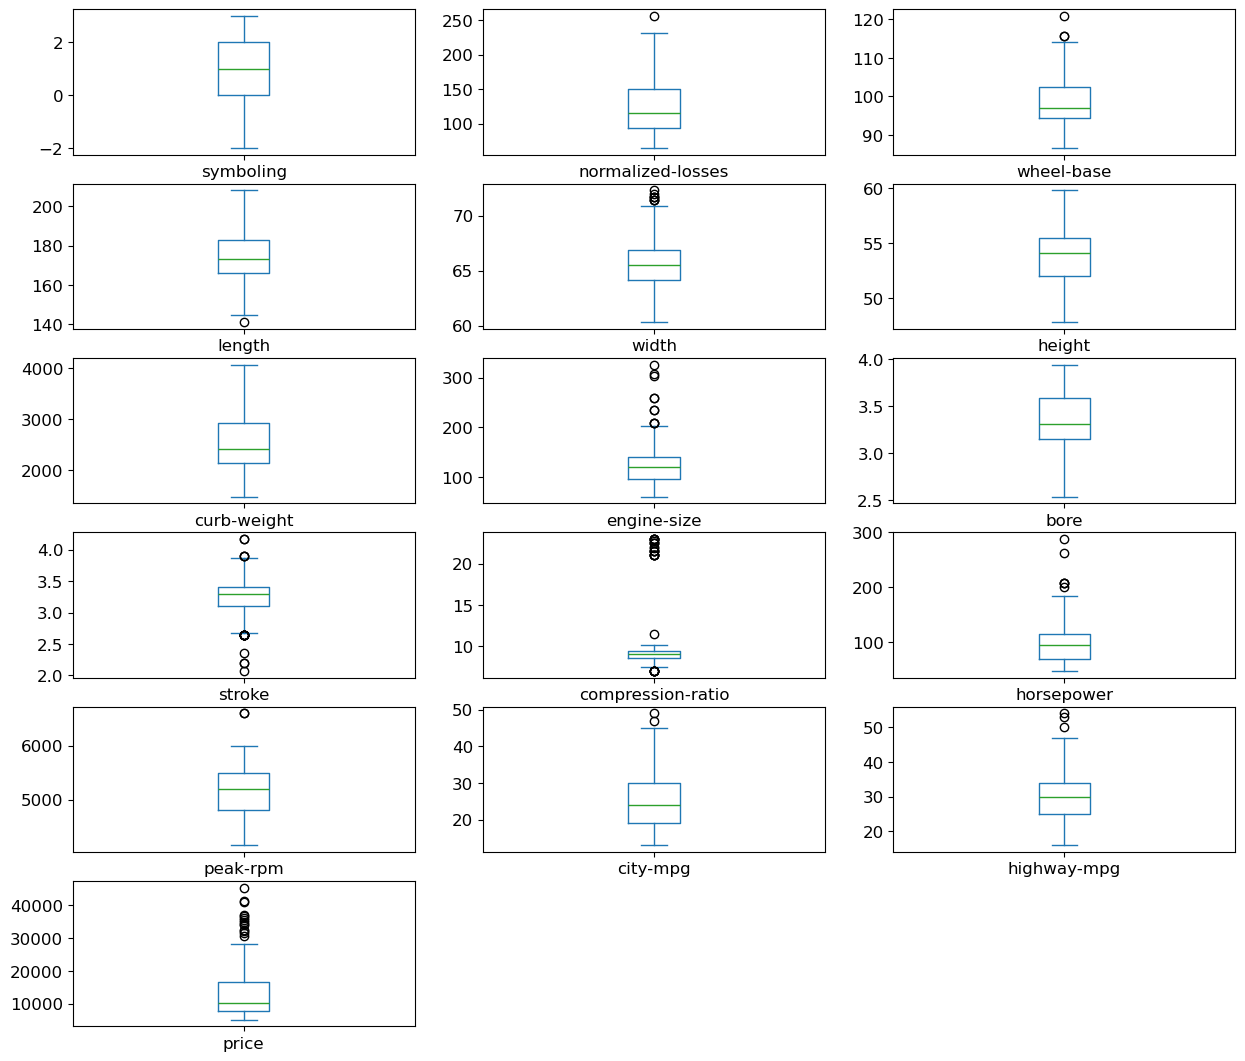

In [111]:
# PLot box plots to visualise the value ranges and outliers of the features
data_mean = data.iloc[:, :]
data_mean.plot(kind = 'box', subplots = True, layout = (9,3), sharex = False,
               sharey = False, fontsize = 12, figsize = (15, 20));

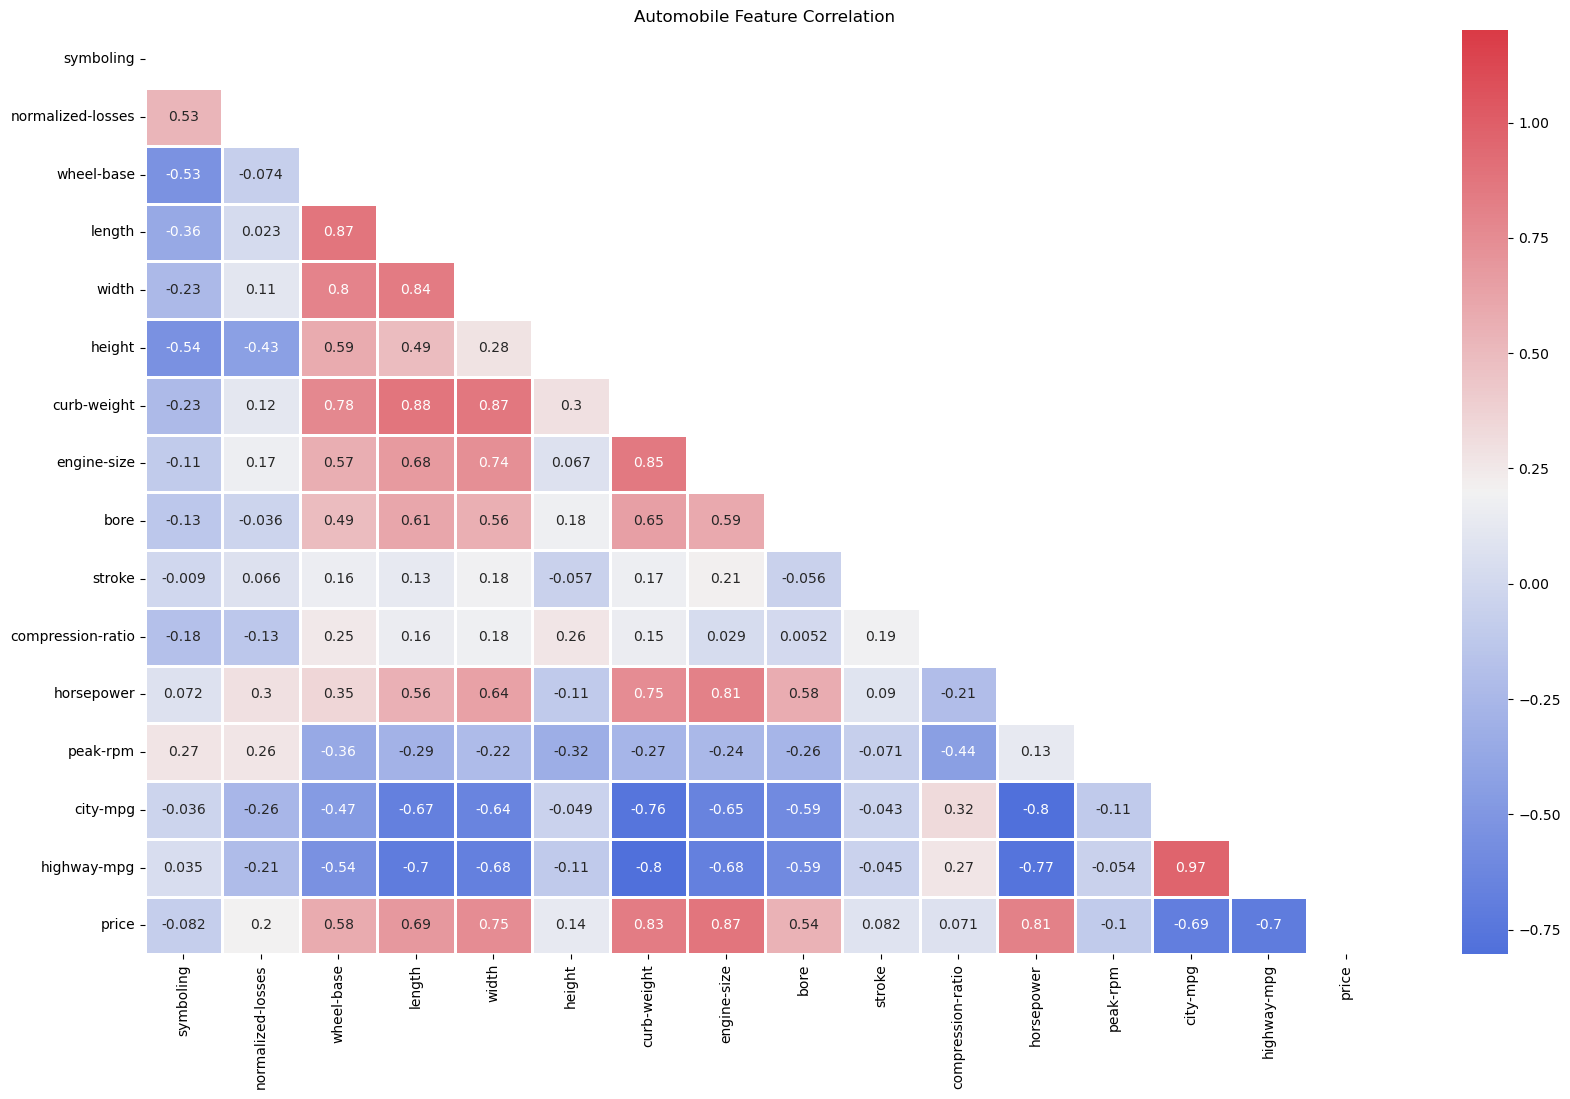

In [112]:
# Compute the correlation matrix to observe the correlations between pairs of features
# Find the correlation between the columns in the dataframe
corrMatt = data.corr(numeric_only=True)

# Generate a mask for the upper triangle
mask = np.zeros_like(corrMatt)
mask[np.triu_indices_from(mask)] = True

# Set up the matplotlib figure
fig, ax = plt.subplots(figsize=(20, 12))
plt.title('Automobile Feature Correlation')

# Generate a custom diverging colormap
cmap = sns.diverging_palette(260, 10, as_cmap=True)

# Draw the heatmap with the mask and correct aspect ratio
sns.heatmap(corrMatt, vmax=1.2, square=False, cmap=cmap, mask=mask,
ax=ax, annot=True, fmt='.2g', linewidths=1);

In [113]:
# Data Pre-processing stuff

In [114]:
# Identifies Target and Handles Missing Targets

target_variable = 'price'
print(f"Target variable: {target_variable}")

# Drops rows where the target ('price') is missing
initial_rows = data.shape[0]
data.dropna(subset=[target_variable], axis=0, inplace=True)
print(f"Dropped {initial_rows - data.shape[0]} rows with missing target. New shape: {data.shape}")

Target variable: price
Dropped 4 rows with missing target. New shape: (201, 26)


In [115]:
# Handles Missing Features (this uses manual imputation based on Lab 2's SimpleImputer principles)

# Imputes numerical features with the mean
numerical_cols_to_impute = ['normalized-losses', 'bore', 'stroke', 'horsepower', 'peak-rpm', 'price']
for col in numerical_cols_to_impute:
    # Ensures column is numeric first
    data[col] = pd.to_numeric(data[col], errors='coerce')
    mean_val = data[col].mean()
    data[col].fillna(mean_val, inplace=True)
    print(f"Filled NaNs in numerical '{col}' with mean.")

# Imputes categorical features with the mode
categorical_cols_to_impute = ['num-of-doors']
for col in categorical_cols_to_impute:
    mode_val = data[col].mode()[0]
    data[col].fillna(mode_val, inplace=True)
    print(f"Filled NaNs in categorical '{col}' with mode.")

print("\nMissing values check after imputation:")
print(data.isnull().sum())

Filled NaNs in numerical 'normalized-losses' with mean.
Filled NaNs in numerical 'bore' with mean.
Filled NaNs in numerical 'stroke' with mean.
Filled NaNs in numerical 'horsepower' with mean.
Filled NaNs in numerical 'peak-rpm' with mean.
Filled NaNs in numerical 'price' with mean.
Filled NaNs in categorical 'num-of-doors' with mode.

Missing values check after imputation:
symboling            0
normalized-losses    0
make                 0
fuel-type            0
aspiration           0
num-of-doors         0
body-style           0
drive-wheels         0
engine-location      0
wheel-base           0
length               0
width                0
height               0
curb-weight          0
engine-type          0
num-of-cylinders     0
engine-size          0
fuel-system          0
bore                 0
stroke               0
compression-ratio    0
horsepower           0
peak-rpm             0
city-mpg             0
highway-mpg          0
price                0
dtype: int64


/var/folders/vy/_kvxm4j56m5c13v4p21nl2hc0000gn/T/ipykernel_23464/1488601130.py:9: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data[col].fillna(mean_val, inplace=True)
/var/folders/vy/_kvxm4j56m5c13v4p21nl2hc0000gn/T/ipykernel_23464/1488601130.py:16: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always beha

In [116]:
# Data before normalisation
data

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,122.0,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0
1,3,122.0,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0
2,1,122.0,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0
3,2,164.0,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950.0
4,2,164.0,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,-1,95.0,volvo,gas,std,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114.0,5400.0,23,28,16845.0
201,-1,95.0,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,8.7,160.0,5300.0,19,25,19045.0
202,-1,95.0,volvo,gas,std,four,sedan,rwd,front,109.1,...,173,mpfi,3.58,2.87,8.8,134.0,5500.0,18,23,21485.0
203,-1,95.0,volvo,diesel,turbo,four,sedan,rwd,front,109.1,...,145,idi,3.01,3.40,23.0,106.0,4800.0,26,27,22470.0


In [117]:
# Data after normalisation

from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
data[numerical_cols_to_impute] = scaler.fit_transform(data[numerical_cols_to_impute])
data

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,0.298429,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,0.664286,0.290476,9.0,0.294393,0.346939,21,27,0.207959
1,3,0.298429,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,0.664286,0.290476,9.0,0.294393,0.346939,21,27,0.282558
2,1,0.298429,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,0.100000,0.666667,9.0,0.495327,0.346939,19,26,0.282558
3,2,0.518325,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,0.464286,0.633333,10.0,0.252336,0.551020,24,30,0.219254
4,2,0.518325,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,0.464286,0.633333,8.0,0.313084,0.551020,18,22,0.306142
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,-1,0.157068,volvo,gas,std,four,sedan,rwd,front,109.1,...,141,mpfi,0.885714,0.514286,9.5,0.308411,0.510204,23,28,0.291123
201,-1,0.157068,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,0.885714,0.514286,8.7,0.523364,0.469388,19,25,0.345738
202,-1,0.157068,volvo,gas,std,four,sedan,rwd,front,109.1,...,173,mpfi,0.742857,0.380952,8.8,0.401869,0.551020,18,23,0.406311
203,-1,0.157068,volvo,diesel,turbo,four,sedan,rwd,front,109.1,...,145,idi,0.335714,0.633333,23.0,0.271028,0.265306,26,27,0.430763


<Axes: >

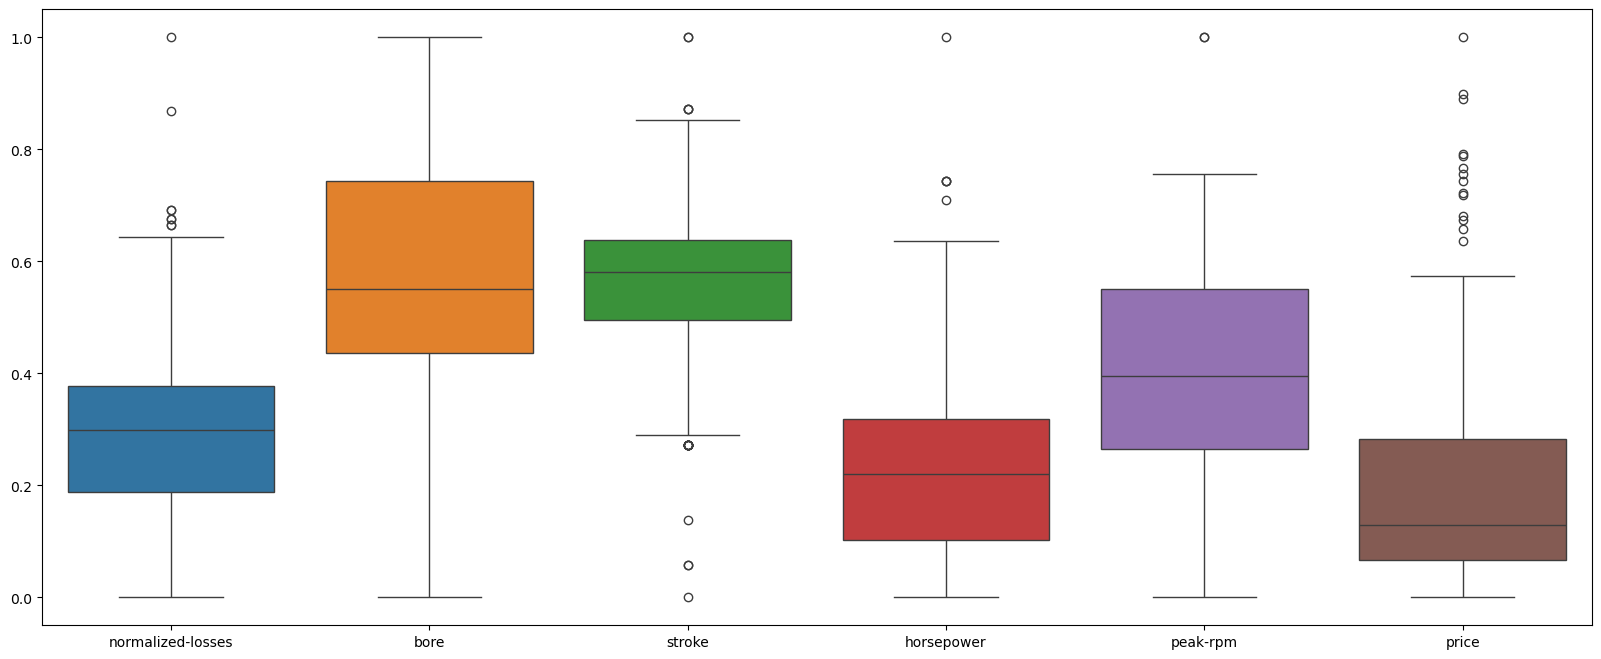

In [118]:
# PLot box plots to see the new value ranges and remainining outliers for normalised features
fig, ax = plt.subplots(1, figsize = (20,8))
sns.boxplot(data = data[numerical_cols_to_impute], ax = ax)

In [119]:
# Encoding Categorical Features (using pd.get_dummies, a pandas equivalent of OneHotEncoder we saw in Lab 2)
# Only did this because I'd have to use a ColumnTransformer to specify which columns to apply it to, while also leaving the numerical columns alone which is just more complex.

categorical_cols = data.select_dtypes(include='object').columns
print(f"\nCategorical columns to encode: {list(categorical_cols)}")
data_encoded = pd.get_dummies(data, columns=categorical_cols, drop_first=True)
print(f"Shape after encoding: {data_encoded.shape}")


Categorical columns to encode: ['make', 'fuel-type', 'aspiration', 'num-of-doors', 'body-style', 'drive-wheels', 'engine-location', 'engine-type', 'num-of-cylinders', 'fuel-system']
Shape after encoding: (201, 65)


In [120]:
# Final X and y Split
# Convert target 'price' to numeric (if it's not already)
data_encoded[target_variable] = pd.to_numeric(data_encoded[target_variable], errors='coerce')

X = data_encoded.drop(target_variable, axis=1)
y = data_encoded[target_variable]

print(f"\nFeatures (X) and Target (y) separated.")
print(f"X shape: {X.shape}, y shape: {y.shape}")


Features (X) and Target (y) separated.
X shape: (201, 64), y shape: (201,)


In [121]:
# 4. Model Definition & Evaluation Setup

In [122]:
# Defining Models (from Labs 1, 3, 4) 
# Going to use random_state for reproducible results
models_reg = {
    'Linear Regression': LinearRegression(),
    'SVR': SVR(), 
    'Decision Tree Regressor': DecisionTreeRegressor(random_state=42),
    'MLP Regressor': MLPRegressor(random_state=1, max_iter=1000)
}
print("\nModels defined.")


Models defined.


In [123]:
# Setup K-Fold Cross-Validation
K = 5 # I just chose this
kf = KFold(n_splits=K, shuffle=True, random_state=42)
print(f"Using K={K} for Cross-Validation.")

Using K=5 for Cross-Validation.


In [124]:
# Sets scoring metric from the Brief
scoring_metric = 'neg_mean_squared_error'
metric_name = 'Mean Squared Error (MSE)'
print(f"Task: regression, Evaluation Metric: {metric_name}")

Task: regression, Evaluation Metric: Mean Squared Error (MSE)


In [125]:
# Run K-Fold Cross-Validation

In [126]:
# We use a Pipeline to combine scaling and modeling,
# Going to use StandardScaler which is from Lab 2 and cross_val_score from Lab 5

results = {}

print(f"\n--- Running {K}-Fold Cross-Validation ---")

for model_name, model in models_reg.items():
    
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('model', model)           
    ])

    # Performs K-Fold Cross-Validation
    scores = cross_val_score(pipeline, X, y, cv=kf, scoring=scoring_metric, n_jobs=-1)

    mean_score = -np.mean(scores)
    std_dev_score = np.std(scores)

    results[model_name] = {'Mean MSE': mean_score, 'Std Dev MSE': std_dev_score}
    print(f"{model_name}: Mean MSE = {mean_score:,.2f} (+/- {std_dev_score:,.2f})")


--- Running 5-Fold Cross-Validation ---
Linear Regression: Mean MSE = 0.00 (+/- 0.00)
SVR: Mean MSE = 0.01 (+/- 0.00)
Decision Tree Regressor: Mean MSE = 0.00 (+/- 0.00)
MLP Regressor: Mean MSE = 0.05 (+/- 0.01)


In [127]:
# Collate Results for Report

In [128]:
results_df = pd.DataFrame(results).T
print("\n--- Summary Table for Report ---")
print(pd.DataFrame(results).T)
print("\nRegression task complete.")


--- Summary Table for Report ---
                         Mean MSE  Std Dev MSE
Linear Regression        0.004669     0.001282
SVR                      0.009771     0.003438
Decision Tree Regressor  0.004175     0.001259
MLP Regressor            0.049124     0.012202

Regression task complete.
